# M5: Text Mining & NLP Analysis

**Issues:** 18–19 (Review 2)

This notebook implements:
- **Word Frequency Analysis** — most common terms in high-rated vs low-rated movies
- **Word Clouds** — visual representation of dominant terms by rating group & genre
- **Topic Modelling (LDA)** — discover hidden themes across movie overviews
- **Sentiment Analysis** — measure emotional tone and its link to ratings
- **Genre-wise & Temporal Text Analysis** — how language differs across genres and decades

Data source: `data/processed/tmdb_clean.csv` (15,386 cleaned movies)

In [1]:
import pandas as pd
import numpy as np
import ast, re, warnings
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from wordcloud import WordCloud
from textblob import TextBlob
from collections import Counter

warnings.filterwarnings('ignore')
sns.set_style("whitegrid")
print("All imports successful.")

All imports successful.


## 1. Load and Prepare Data

In [2]:
# Load cleaned dataset
df = pd.read_csv("../data/processed/tmdb_clean.csv", parse_dates=["release_date"])
df["genres"] = df["genres"].apply(ast.literal_eval)

# Use only movies with 20+ votes (reliable ratings)
m = df[df["vote_count"] >= 20].copy()
m["high_rated"] = (m["vote_average"] >= 6.5).astype(int)
m["decade"] = (m["release_year"] // 10 * 10).astype(str) + "s"

print(f"Total clean movies: {len(df):,}")
print(f"Movies for analysis (20+ votes): {len(m):,}")
print(f"High-rated: {m['high_rated'].sum():,} ({m['high_rated'].mean():.1%})")
print(f"Low-rated: {(m['high_rated']==0).sum():,} ({(m['high_rated']==0).mean():.1%})")

Total clean movies: 15,386
Movies for analysis (20+ votes): 10,078
High-rated: 3,931 (39.0%)
Low-rated: 6,147 (61.0%)


## 2. Text Preprocessing

In [3]:
def clean_text(text):
    '''Lowercase, remove non-alpha, collapse whitespace.'''
    if pd.isna(text) or text.strip() == "":
        return ""
    text = text.lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

m["clean"] = m["overview"].apply(clean_text)

# Quick stats
m["word_count"] = m["clean"].str.split().str.len()
print(f"Avg words per overview: {m['word_count'].mean():.1f}")
print(f"Min: {m['word_count'].min()}, Max: {m['word_count'].max()}")
print(f"\nSample cleaned text:\n{m['clean'].iloc[0][:200]}...")

Avg words per overview: 49.6
Min: 3, Max: 195

Sample cleaned text:
the story of the legendary steel driving folk hero born with a hammer in his hands who pitted his strength against a mighty railroad building machine...


In [4]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# Custom stop words: English defaults + generic movie terms
custom_stops = list(ENGLISH_STOP_WORDS) + [
    "film", "movie", "story", "life", "finds", "new", "one", "two",
    "must", "world", "man", "young", "woman", "find", "group", "takes",
    "set", "help", "time", "day", "back", "old", "gets", "makes", "just"
]
print(f"Total stop words: {len(set(custom_stops))}")

Total stop words: 338


---
## 3. Word Frequency Analysis: High-Rated vs Low-Rated

Compare the most frequently used words in high-rated movie overviews versus low-rated ones to identify thematic differences.

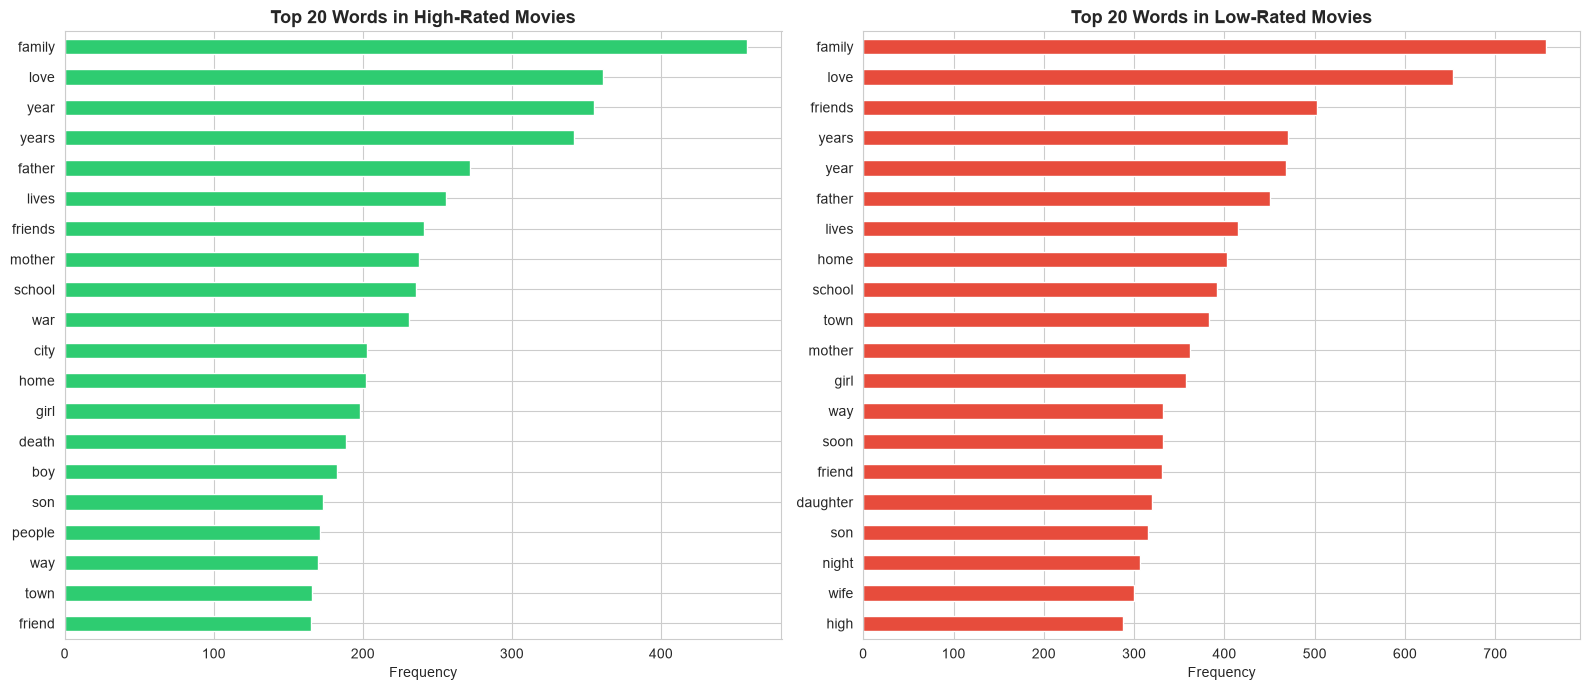

Saved: word_freq_high_vs_low.png


In [5]:
# Split texts by rating group
high_texts = m[m["high_rated"] == 1]["clean"]
low_texts = m[m["high_rated"] == 0]["clean"]

def get_word_freq(texts, stop_words):
    all_words = []
    for text in texts:
        words = [w for w in text.split() if w not in stop_words and len(w) > 2]
        all_words.extend(words)
    return Counter(all_words)

high_freq = get_word_freq(high_texts, set(custom_stops))
low_freq = get_word_freq(low_texts, set(custom_stops))

# Top 20 words per group
top_high = pd.Series(dict(high_freq.most_common(20)))
top_low = pd.Series(dict(low_freq.most_common(20)))

fig, ax = plt.subplots(1, 2, figsize=(16, 7))
top_high.sort_values().plot(kind="barh", ax=ax[0], color="#2ecc71", edgecolor="white")
ax[0].set_title("Top 20 Words in High-Rated Movies", fontsize=13, fontweight="bold")
ax[0].set_xlabel("Frequency")

top_low.sort_values().plot(kind="barh", ax=ax[1], color="#e74c3c", edgecolor="white")
ax[1].set_title("Top 20 Words in Low-Rated Movies", fontsize=13, fontweight="bold")
ax[1].set_xlabel("Frequency")

plt.tight_layout()
plt.savefig("../data/processed/word_freq_high_vs_low.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: word_freq_high_vs_low.png")

### 3.1 Differential Terms (TF-IDF)

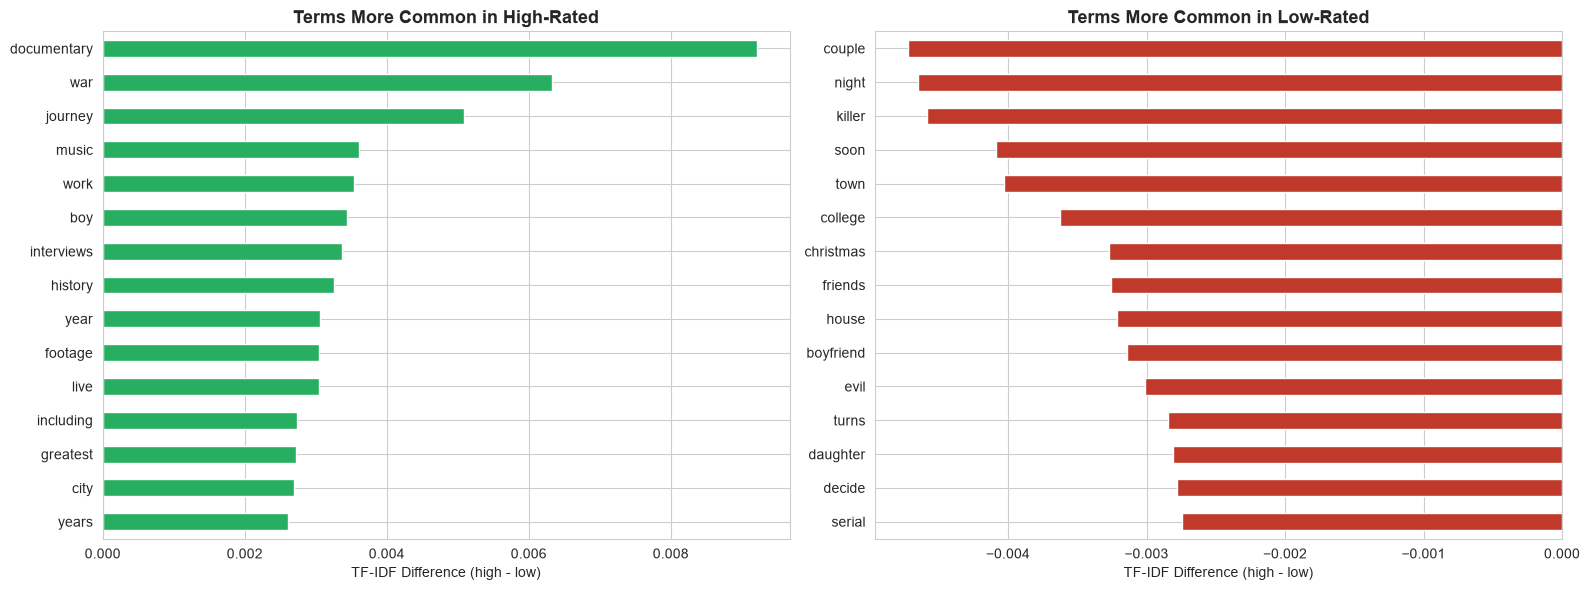

Top terms in HIGH-RATED overviews:
  documentary                +0.0092
  war                        +0.0063
  journey                    +0.0051
  music                      +0.0036
  work                       +0.0035
  boy                        +0.0034
  interviews                 +0.0034
  history                    +0.0033
  year                       +0.0031
  footage                    +0.0030
  live                       +0.0030
  including                  +0.0027
  greatest                   +0.0027
  city                       +0.0027
  years                      +0.0026

Top terms in LOW-RATED overviews:
  couple                     -0.0047
  night                      -0.0047
  killer                     -0.0046
  soon                       -0.0041
  town                       -0.0040
  college                    -0.0036
  christmas                  -0.0033
  friends                    -0.0033
  house                      -0.0032
  boyfriend                  -0.0031
  evi

In [6]:
# TF-IDF fitted on all modelling data
tfidf = TfidfVectorizer(stop_words=list(set(custom_stops)), max_features=1000,
                         ngram_range=(1, 2), min_df=5)
T = tfidf.fit_transform(m["clean"])
terms = np.array(tfidf.get_feature_names_out())

hi_mask = (m["high_rated"] == 1).values
diff = np.asarray(T[hi_mask].mean(axis=0)).ravel() - np.asarray(T[~hi_mask].mean(axis=0)).ravel()

top_high_tfidf = pd.Series(diff, index=terms).sort_values(ascending=False).head(15)
top_low_tfidf = pd.Series(diff, index=terms).sort_values(ascending=True).head(15)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
top_high_tfidf.sort_values().plot(kind="barh", ax=ax[0], color="#27ae60")
ax[0].set_title("Terms More Common in High-Rated", fontsize=13, fontweight="bold")
ax[0].set_xlabel("TF-IDF Difference (high - low)")

top_low_tfidf.sort_values(ascending=False).plot(kind="barh", ax=ax[1], color="#c0392b")
ax[1].set_title("Terms More Common in Low-Rated", fontsize=13, fontweight="bold")
ax[1].set_xlabel("TF-IDF Difference (high - low)")

plt.tight_layout()
plt.savefig("../data/processed/differential_terms.png", dpi=150, bbox_inches="tight")
plt.show()

print("Top terms in HIGH-RATED overviews:")
for t, v in top_high_tfidf.items():
    print(f"  {t:25s}  +{v:.4f}")
print("\nTop terms in LOW-RATED overviews:")
for t, v in top_low_tfidf.items():
    print(f"  {t:25s}  {v:.4f}")

---
## 4. Word Clouds

Visual representation of dominant terms in high-rated versus low-rated movie overviews.

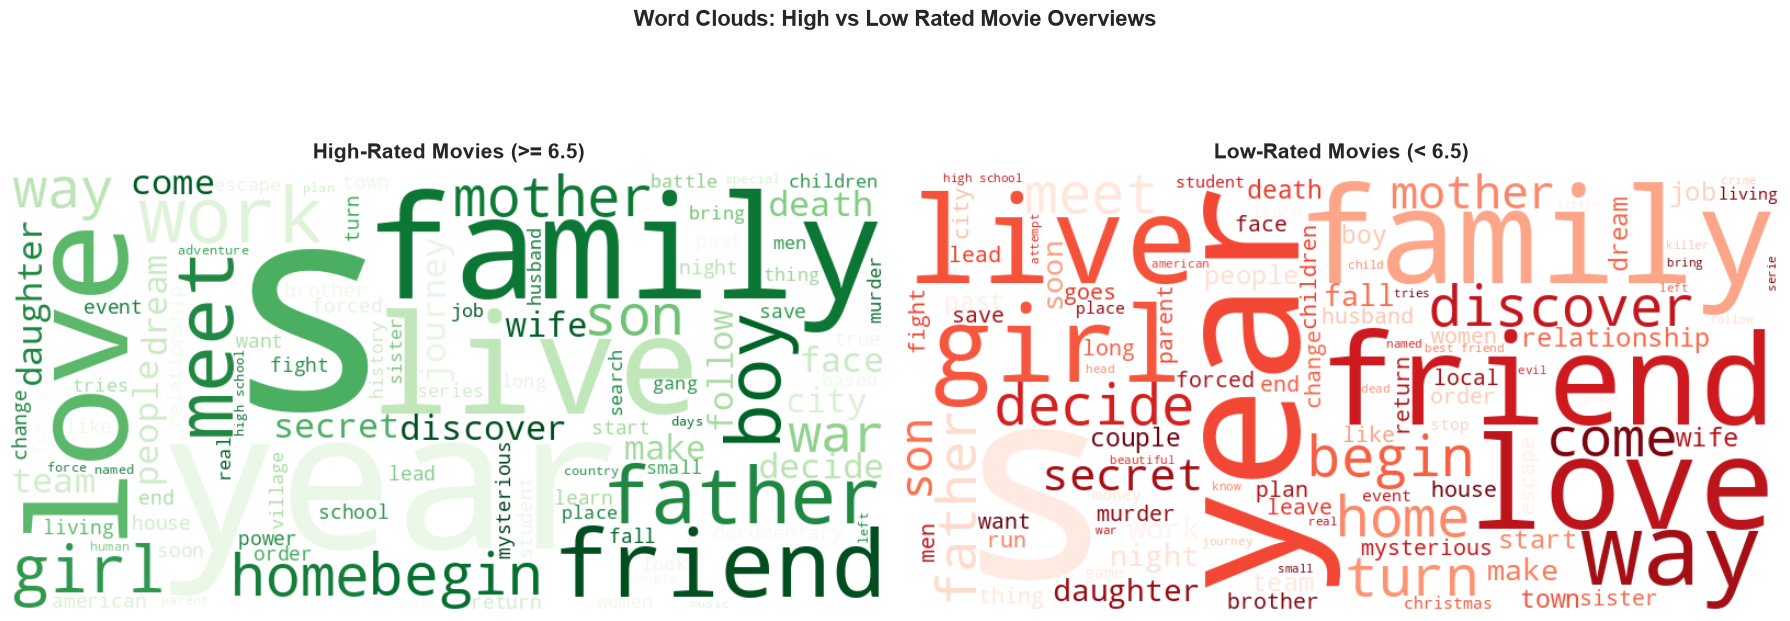

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(18, 7))

wc_high = WordCloud(width=800, height=400, background_color="white",
                     colormap="Greens", max_words=100,
                     stopwords=set(custom_stops)).generate(" ".join(high_texts))
ax[0].imshow(wc_high, interpolation="bilinear")
ax[0].set_title("High-Rated Movies (>= 6.5)", fontsize=15, fontweight="bold", pad=10)
ax[0].axis("off")

wc_low = WordCloud(width=800, height=400, background_color="white",
                    colormap="Reds", max_words=100,
                    stopwords=set(custom_stops)).generate(" ".join(low_texts))
ax[1].imshow(wc_low, interpolation="bilinear")
ax[1].set_title("Low-Rated Movies (< 6.5)", fontsize=15, fontweight="bold", pad=10)
ax[1].axis("off")

plt.suptitle("Word Clouds: High vs Low Rated Movie Overviews", fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("../data/processed/wordclouds_rating.png", dpi=150, bbox_inches="tight")
plt.show()

### 4.1 Word Clouds by Genre

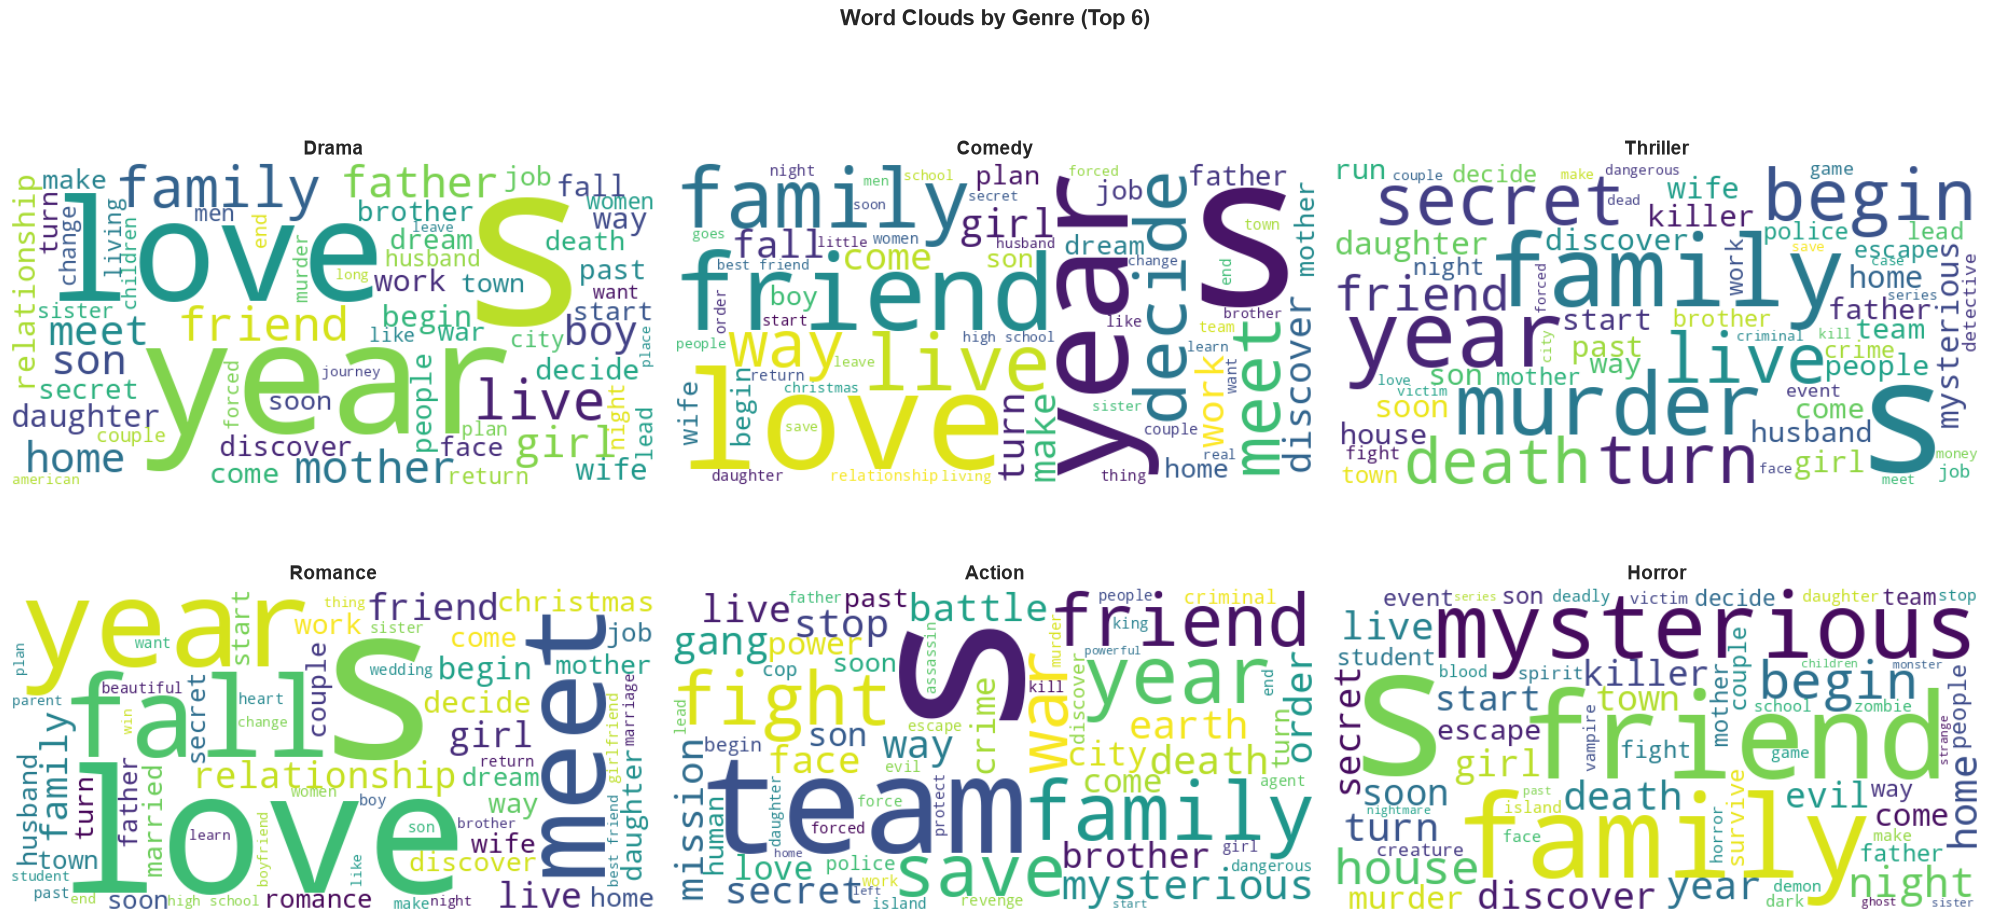

In [8]:
# Word clouds for top 6 genres by movie count
g = m.explode("genres").reset_index(drop=True)
top_genres = g["genres"].value_counts().head(6).index.tolist()

fig, axes = plt.subplots(2, 3, figsize=(20, 10))
for i, genre in enumerate(top_genres):
    ax = axes[i // 3, i % 3]
    genre_text = " ".join(g[g["genres"] == genre]["clean"])
    wc = WordCloud(width=600, height=300, background_color="white",
                    colormap="viridis", max_words=60,
                    stopwords=set(custom_stops)).generate(genre_text)
    ax.imshow(wc, interpolation="bilinear")
    ax.set_title(genre, fontsize=14, fontweight="bold")
    ax.axis("off")

plt.suptitle("Word Clouds by Genre (Top 6)", fontsize=16, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig("../data/processed/wordclouds_genre.png", dpi=150, bbox_inches="tight")
plt.show()

---
## 5. Topic Modelling (Latent Dirichlet Allocation)

LDA discovers hidden "topics" — groups of words that frequently co-occur across overviews. Each movie gets a distribution over topics.

In [9]:
# Use CountVectorizer for LDA (needs raw counts, not TF-IDF)
count_vec = CountVectorizer(stop_words=list(set(custom_stops)), max_features=2000,
                             ngram_range=(1, 1), min_df=10, max_df=0.7)
doc_term = count_vec.fit_transform(m["clean"])
feature_names = count_vec.get_feature_names_out()

# Fit LDA with 8 topics
N_TOPICS = 8
lda = LatentDirichletAllocation(n_components=N_TOPICS, random_state=42,
                                  max_iter=20, learning_method="online")
topic_dist = lda.fit_transform(doc_term)

print(f"Documents: {doc_term.shape[0]:,}")
print(f"Vocabulary: {doc_term.shape[1]:,}")
print(f"Topics discovered: {N_TOPICS}")
print(f"Log-likelihood: {lda.score(doc_term):.0f}")
print(f"Perplexity: {lda.perplexity(doc_term):.0f}")

Documents: 10,078
Vocabulary: 2,000
Topics discovered: 8


Log-likelihood: -1113988


Perplexity: 1899


### 5.1 Discovered Topics

In [10]:
# Display top words per topic
def display_topics(model, feature_names, n_words=10):
    topics = []
    for i, topic in enumerate(model.components_):
        top_words = [feature_names[j] for j in topic.argsort()[:-n_words-1:-1]]
        topics.append({"Topic": f"Topic {i+1}", "Top Words": ", ".join(top_words)})
        print(f"Topic {i+1}: {', '.join(top_words)}")
    return pd.DataFrame(topics)

print("=== Discovered Topics (Top 10 Words Each) ===\n")
topic_df = display_topics(lda, feature_names, n_words=10)

=== Discovered Topics (Top 10 Words Each) ===

Topic 1: war, search, documentary, game, based, true, adventure, agent, history, detective
Topic 2: police, murder, killer, dead, case, crime, criminal, missing, following, investigation
Topic 3: friends, couple, night, home, turns, relationship, married, soon, comes, begins
Topic 4: family, father, brother, like, way, money, year, face, friends, people
Topic 5: school, high, year, days, student, people, team, different, girl, middle
Topic 6: father, year, parents, mysterious, leads, friend, mother, home, begins, death
Topic 7: love, son, family, daughter, wife, meets, falls, girl, village, star
Topic 8: town, past, family, christmas, small, away, years, island, plan, city


### 5.2 Topic vs Rating Analysis

=== Rating by Dominant Topic ===
                count  avg_rating  high_rated_pct  avg_popularity
dominant_topic                                                   
1                1266       6.268           0.474           3.555
2                 719       5.967           0.316           3.478
3                1241       5.997           0.336           3.205
4                2515       6.085           0.380           3.495
5                1062       6.171           0.416           3.192
6                1131       6.158           0.402           3.507
7                1128       6.224           0.415           3.204
8                1016       6.091           0.360           3.534


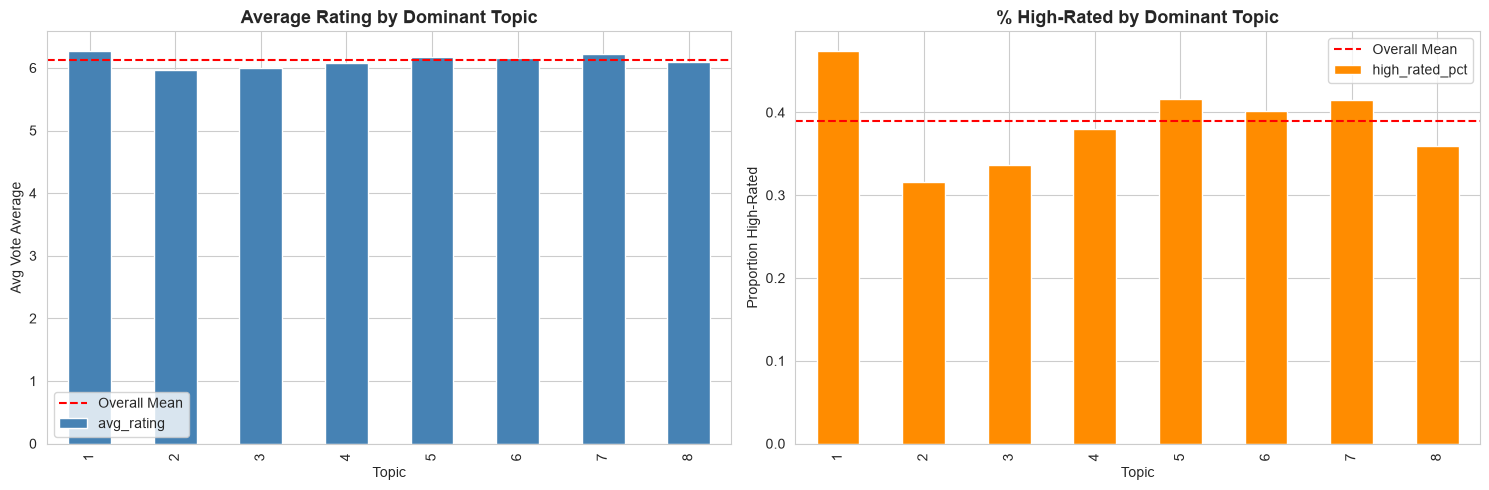

In [11]:
# Assign dominant topic to each movie
m["dominant_topic"] = topic_dist.argmax(axis=1) + 1

# Average rating per dominant topic
topic_rating = m.groupby("dominant_topic").agg(
    count=("high_rated", "count"),
    avg_rating=("vote_average", "mean"),
    high_rated_pct=("high_rated", "mean"),
    avg_popularity=("popularity", "mean")
).round(3)

print("=== Rating by Dominant Topic ===")
print(topic_rating.to_string())

fig, ax = plt.subplots(1, 2, figsize=(15, 5))

topic_rating["avg_rating"].plot(kind="bar", ax=ax[0], color="steelblue", edgecolor="white")
ax[0].set_title("Average Rating by Dominant Topic", fontsize=13, fontweight="bold")
ax[0].set_xlabel("Topic")
ax[0].set_ylabel("Avg Vote Average")
ax[0].axhline(y=m["vote_average"].mean(), color="red", linestyle="--", label="Overall Mean")
ax[0].legend()

topic_rating["high_rated_pct"].plot(kind="bar", ax=ax[1], color="darkorange", edgecolor="white")
ax[1].set_title("% High-Rated by Dominant Topic", fontsize=13, fontweight="bold")
ax[1].set_xlabel("Topic")
ax[1].set_ylabel("Proportion High-Rated")
ax[1].axhline(y=m["high_rated"].mean(), color="red", linestyle="--", label="Overall Mean")
ax[1].legend()

plt.tight_layout()
plt.savefig("../data/processed/topic_vs_rating.png", dpi=150, bbox_inches="tight")
plt.show()

### 5.3 Topic-Genre Heatmap

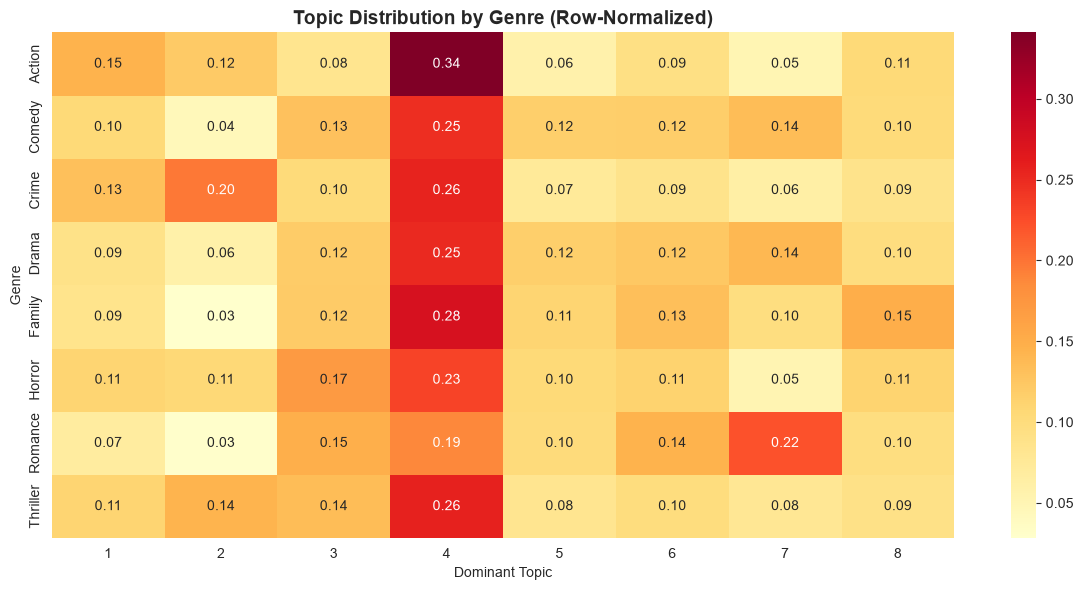


Each row shows what fraction of movies in that genre belong to each topic.


In [12]:
# Cross-tabulate dominant topic vs genre
g_topics = m.explode("genres").reset_index(drop=True)
top_genres_8 = g_topics["genres"].value_counts().head(8).index.tolist()
g_topics = g_topics[g_topics["genres"].isin(top_genres_8)]

cross = pd.crosstab(g_topics["genres"], g_topics["dominant_topic"], normalize="index")

fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(cross, annot=True, fmt=".2f", cmap="YlOrRd", ax=ax)
ax.set_title("Topic Distribution by Genre (Row-Normalized)", fontsize=14, fontweight="bold")
ax.set_xlabel("Dominant Topic")
ax.set_ylabel("Genre")
plt.tight_layout()
plt.savefig("../data/processed/topic_genre_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nEach row shows what fraction of movies in that genre belong to each topic.")

---
## 6. Sentiment Analysis

Measure the polarity (positive/negative tone) and subjectivity (opinion vs fact) of each overview using TextBlob.

In [13]:
# Calculate sentiment scores
m["polarity"] = m["overview"].apply(lambda x: TextBlob(str(x)).sentiment.polarity)
m["subjectivity"] = m["overview"].apply(lambda x: TextBlob(str(x)).sentiment.subjectivity)

print("=== Sentiment Summary ===")
print(m[["polarity", "subjectivity"]].describe().round(3))

print(f"\nBy rating group:")
print(m.groupby("high_rated")[["polarity", "subjectivity"]].mean().round(4).rename(
    index={0: "Low-rated", 1: "High-rated"}))

=== Sentiment Summary ===
        polarity  subjectivity
count  10078.000     10078.000
mean       0.047         0.465
std        0.228         0.227
min       -1.000         0.000
25%       -0.065         0.333
50%        0.034         0.476
75%        0.172         0.601
max        1.000         1.000

By rating group:
            polarity  subjectivity
high_rated                        
Low-rated     0.0364        0.4701
High-rated    0.0647        0.4581


### 6.1 Sentiment Distribution

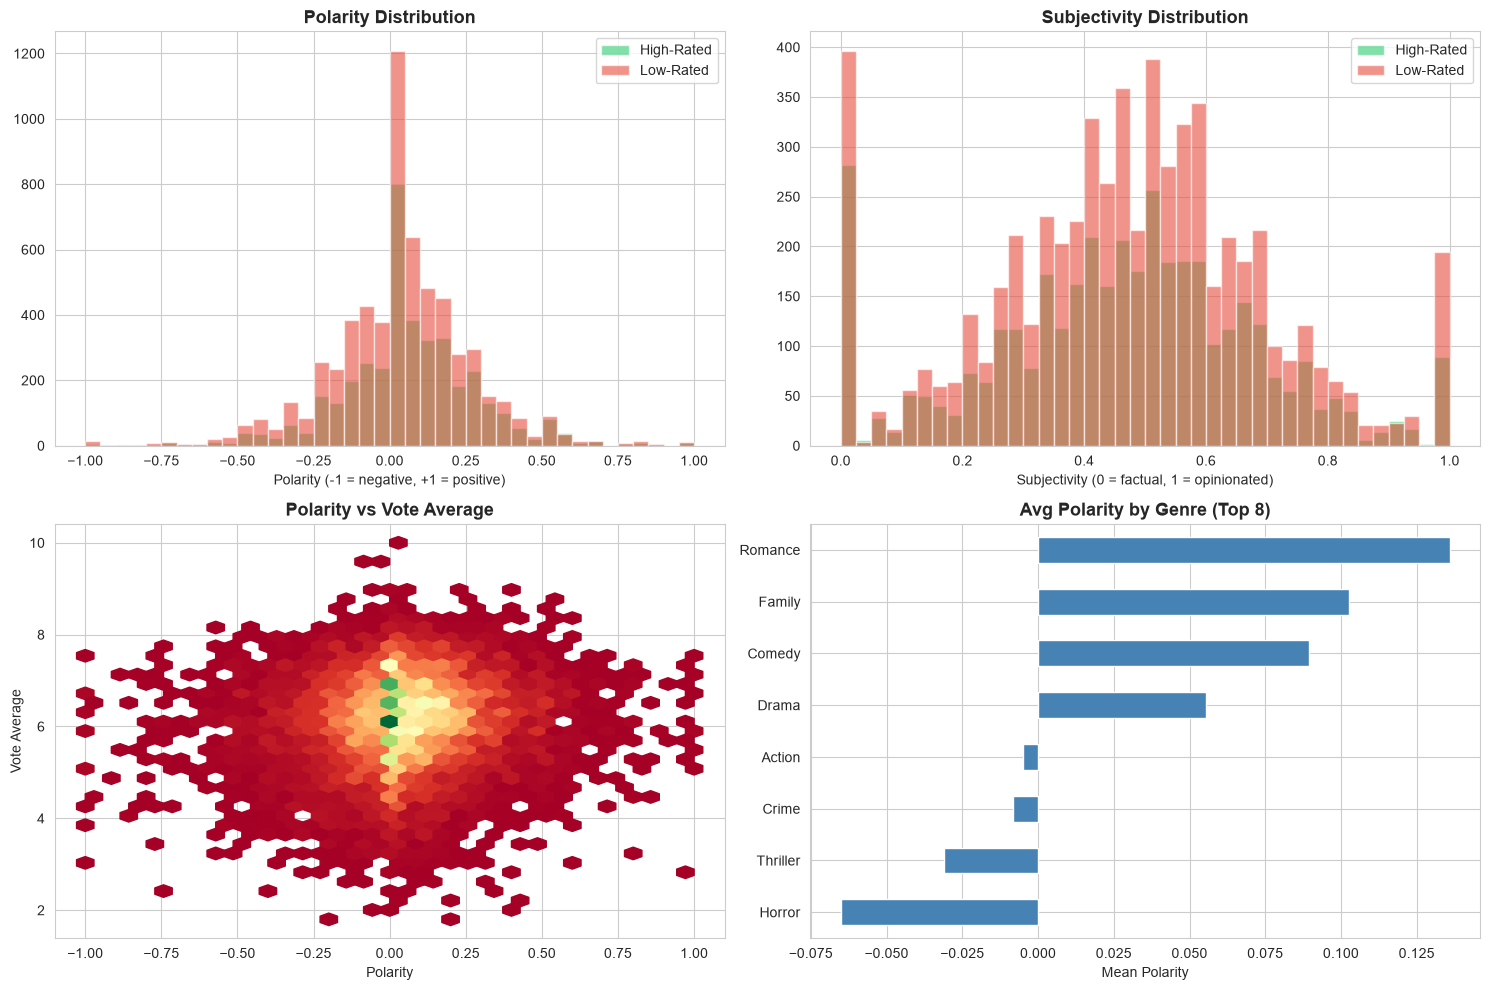

In [14]:
fig, ax = plt.subplots(2, 2, figsize=(15, 10))

# Polarity distribution by rating
for label, color, name in [(1, "#2ecc71", "High-Rated"), (0, "#e74c3c", "Low-Rated")]:
    subset = m[m["high_rated"] == label]["polarity"]
    ax[0, 0].hist(subset, bins=40, alpha=0.6, color=color, label=name, edgecolor="white")
ax[0, 0].set_title("Polarity Distribution", fontsize=13, fontweight="bold")
ax[0, 0].set_xlabel("Polarity (-1 = negative, +1 = positive)")
ax[0, 0].legend()

# Subjectivity distribution by rating
for label, color, name in [(1, "#2ecc71", "High-Rated"), (0, "#e74c3c", "Low-Rated")]:
    subset = m[m["high_rated"] == label]["subjectivity"]
    ax[0, 1].hist(subset, bins=40, alpha=0.6, color=color, label=name, edgecolor="white")
ax[0, 1].set_title("Subjectivity Distribution", fontsize=13, fontweight="bold")
ax[0, 1].set_xlabel("Subjectivity (0 = factual, 1 = opinionated)")
ax[0, 1].legend()

# Polarity vs Rating scatter
ax[1, 0].hexbin(m["polarity"], m["vote_average"], gridsize=35, cmap="RdYlGn", mincnt=1)
ax[1, 0].set_title("Polarity vs Vote Average", fontsize=13, fontweight="bold")
ax[1, 0].set_xlabel("Polarity")
ax[1, 0].set_ylabel("Vote Average")

# Sentiment by genre (top 8)
g_sent = m.explode("genres").reset_index(drop=True)
top8 = g_sent["genres"].value_counts().head(8).index
g_sent = g_sent[g_sent["genres"].isin(top8)]
genre_sent = g_sent.groupby("genres")["polarity"].mean().sort_values()
genre_sent.plot(kind="barh", ax=ax[1, 1], color="steelblue", edgecolor="white")
ax[1, 1].set_title("Avg Polarity by Genre (Top 8)", fontsize=13, fontweight="bold")
ax[1, 1].set_xlabel("Mean Polarity")
ax[1, 1].set_ylabel("")

plt.tight_layout()
plt.savefig("../data/processed/sentiment_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

### 6.2 Sentiment Correlation with Rating

In [15]:
from scipy.stats import spearmanr

corr_pol, p_pol = spearmanr(m["polarity"], m["vote_average"])
corr_sub, p_sub = spearmanr(m["subjectivity"], m["vote_average"])

print("=== Spearman Correlations with Vote Average ===")
print(f"Polarity:     r = {corr_pol:.4f}  (p = {p_pol:.2e})")
print(f"Subjectivity: r = {corr_sub:.4f}  (p = {p_sub:.2e})")
print()
if abs(corr_pol) < 0.1:
    print("Polarity has negligible correlation with rating.")
else:
    direction = "positive" if corr_pol > 0 else "negative"
    print(f"Polarity has a {direction} weak correlation with rating.")

if abs(corr_sub) < 0.1:
    print("Subjectivity has negligible correlation with rating.")
else:
    direction = "positive" if corr_sub > 0 else "negative"
    print(f"Subjectivity has a {direction} weak correlation with rating.")

=== Spearman Correlations with Vote Average ===
Polarity:     r = 0.0833  (p = 5.48e-17)
Subjectivity: r = -0.0346  (p = 5.09e-04)

Polarity has negligible correlation with rating.
Subjectivity has negligible correlation with rating.


---
## 7. Temporal Text Analysis

How has the language of movie overviews changed across decades?

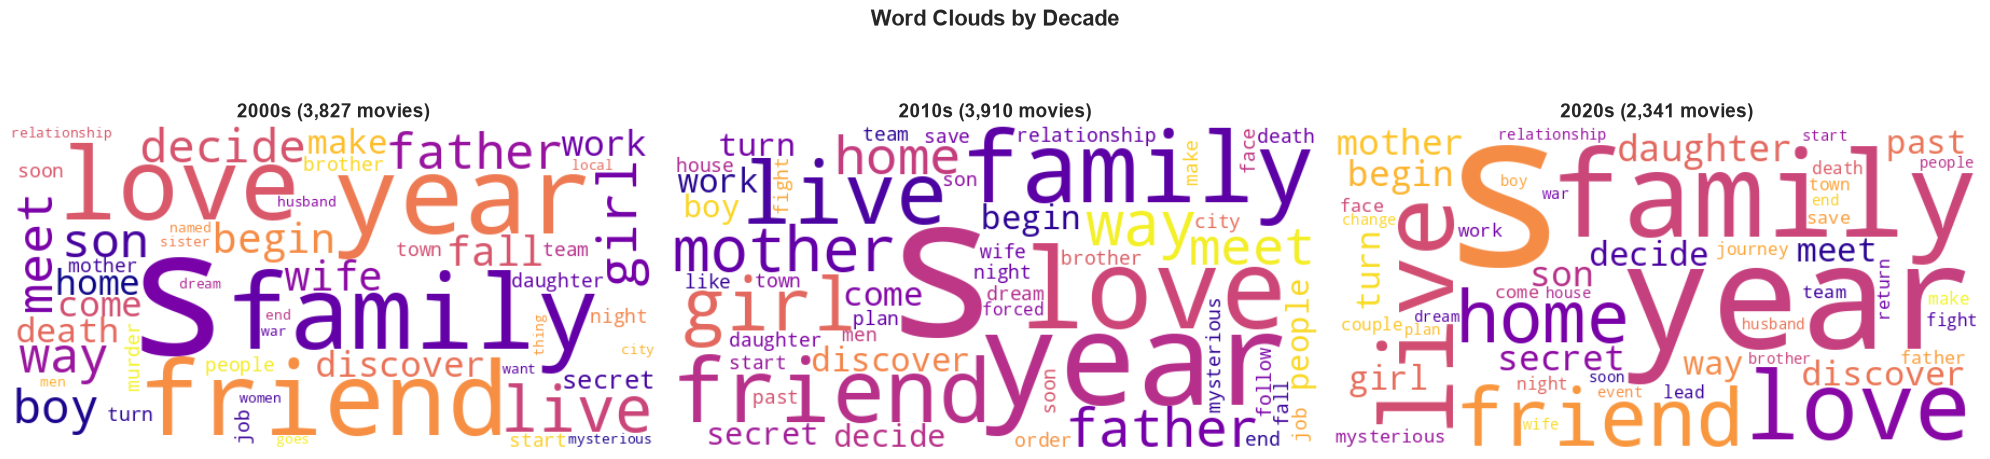

In [16]:
decades = ["2000s", "2010s", "2020s"]
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

for i, decade in enumerate(decades):
    decade_text = " ".join(m[m["decade"] == decade]["clean"])
    wc = WordCloud(width=600, height=300, background_color="white",
                    colormap="plasma", max_words=50,
                    stopwords=set(custom_stops)).generate(decade_text)
    axes[i].imshow(wc, interpolation="bilinear")
    n_movies = (m["decade"] == decade).sum()
    axes[i].set_title(f"{decade} ({n_movies:,} movies)", fontsize=14, fontweight="bold")
    axes[i].axis("off")

plt.suptitle("Word Clouds by Decade", fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("../data/processed/wordclouds_decade.png", dpi=150, bbox_inches="tight")
plt.show()

### 7.1 Sentiment Trends Over Time

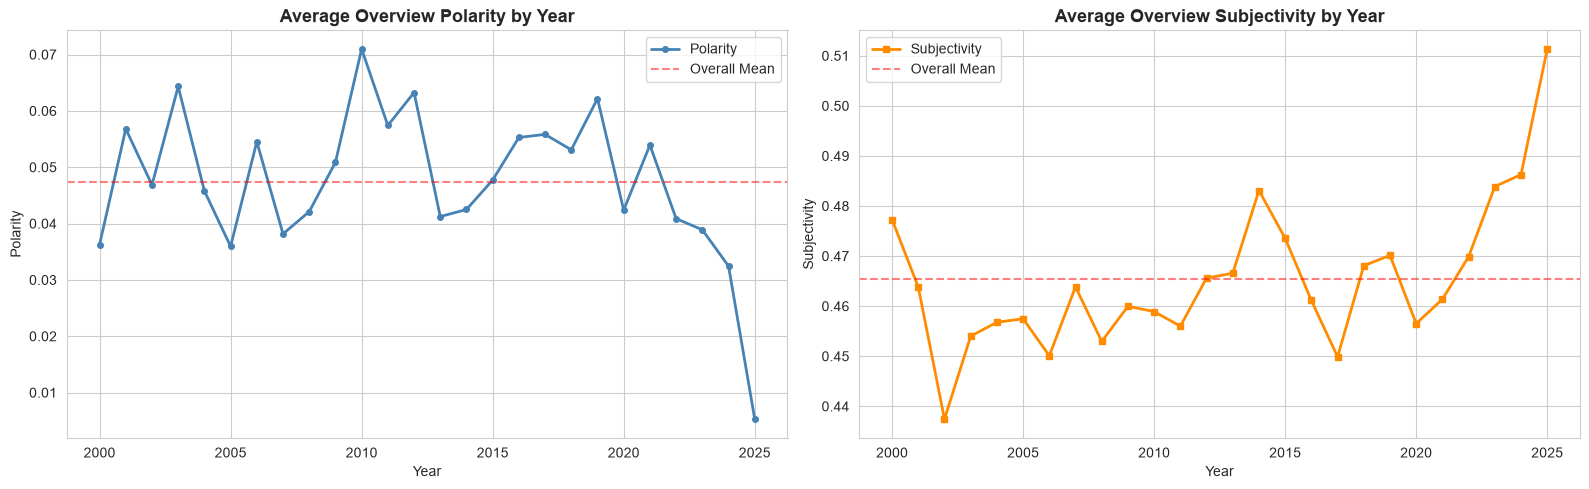

In [17]:
yearly_sent = m.groupby("release_year").agg(
    avg_polarity=("polarity", "mean"),
    avg_subjectivity=("subjectivity", "mean"),
    avg_rating=("vote_average", "mean"),
    count=("high_rated", "count")
)

fig, ax = plt.subplots(1, 2, figsize=(16, 5))

ax[0].plot(yearly_sent.index, yearly_sent["avg_polarity"], color="steelblue",
           marker="o", markersize=4, linewidth=2, label="Polarity")
ax[0].set_title("Average Overview Polarity by Year", fontsize=13, fontweight="bold")
ax[0].set_xlabel("Year")
ax[0].set_ylabel("Polarity")
ax[0].axhline(y=m["polarity"].mean(), color="red", linestyle="--", alpha=0.5, label="Overall Mean")
ax[0].legend()

ax[1].plot(yearly_sent.index, yearly_sent["avg_subjectivity"], color="darkorange",
           marker="s", markersize=4, linewidth=2, label="Subjectivity")
ax[1].set_title("Average Overview Subjectivity by Year", fontsize=13, fontweight="bold")
ax[1].set_xlabel("Year")
ax[1].set_ylabel("Subjectivity")
ax[1].axhline(y=m["subjectivity"].mean(), color="red", linestyle="--", alpha=0.5, label="Overall Mean")
ax[1].legend()

plt.tight_layout()
plt.savefig("../data/processed/sentiment_trends.png", dpi=150, bbox_inches="tight")
plt.show()

---
## 8. Overview Length Analysis

Does the length of a movie overview relate to its rating?

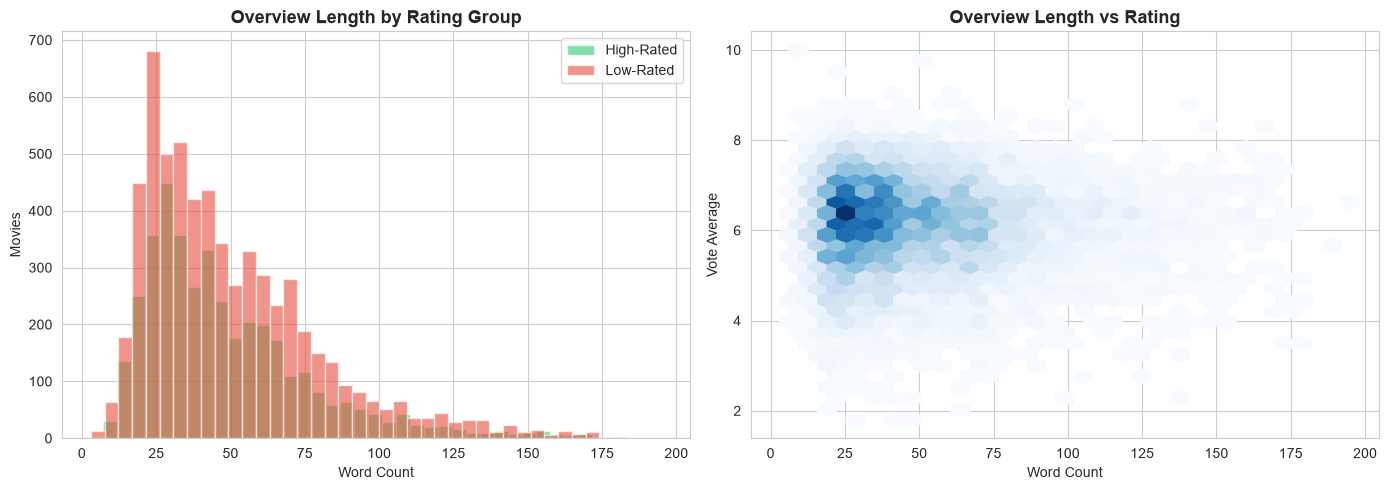

Spearman correlation (word count vs rating): r = -0.0144  (p = 1.49e-01)
Avg words -- High-rated: 48.7 | Low-rated: 50.1


In [18]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Word count distribution by rating group
for label, color, name in [(1, "#2ecc71", "High-Rated"), (0, "#e74c3c", "Low-Rated")]:
    subset = m[m["high_rated"] == label]["word_count"]
    ax[0].hist(subset, bins=40, alpha=0.6, color=color, label=name, edgecolor="white")
ax[0].set_title("Overview Length by Rating Group", fontsize=13, fontweight="bold")
ax[0].set_xlabel("Word Count")
ax[0].set_ylabel("Movies")
ax[0].legend()

# Hexbin: word count vs rating
ax[1].hexbin(m["word_count"], m["vote_average"], gridsize=30, cmap="Blues", mincnt=1)
ax[1].set_title("Overview Length vs Rating", fontsize=13, fontweight="bold")
ax[1].set_xlabel("Word Count")
ax[1].set_ylabel("Vote Average")

plt.tight_layout()
plt.savefig("../data/processed/overview_length.png", dpi=150, bbox_inches="tight")
plt.show()

corr_wc, p_wc = spearmanr(m["word_count"], m["vote_average"])
print(f"Spearman correlation (word count vs rating): r = {corr_wc:.4f}  (p = {p_wc:.2e})")
hi_wc = m[m["high_rated"]==1]["word_count"].mean()
lo_wc = m[m["high_rated"]==0]["word_count"].mean()
print(f"Avg words -- High-rated: {hi_wc:.1f} | Low-rated: {lo_wc:.1f}")

---
## 9. Summary of Text Mining Findings

### Word Frequency & Differential Terms
- High-rated and low-rated movies use overlapping vocabulary, but certain terms appear more in each group.
- Differential TF-IDF reveals thematic differences between the two groups.

### Word Clouds
- Genre-specific word clouds show that overviews naturally reflect their genre — Horror uses words like "killer", "dead", "night"; Documentary uses "life", "history", "world".
- Decade-level clouds show shifts in movie themes over time.

### Topic Modelling (LDA)
- 8 latent topics were discovered across all movie overviews.
- Some topics correlate more with higher or lower average ratings, showing that thematic content has a loose link to audience reception.
- The topic-genre heatmap confirms that LDA topics align with known genres.

### Sentiment Analysis
- Overview polarity (positive/negative tone) and subjectivity (opinion vs fact) have weak correlations with actual ratings.
- This confirms that how a plot summary is written does not determine how audiences rate the film.
- Genre-level sentiment differences exist (e.g., Horror tends to be more negative than Comedy).

### Business Takeaway
- Text features are useful for **interpretation and content insight** — understanding themes, tone, and trends — but they do **not improve prediction accuracy** beyond structured features like genre, language, and vote count.
- Studios can use these insights to understand what themes and language are associated with audience satisfaction.

In [19]:
print("M5 Text Mining & NLP Analysis Complete!")

M5 Text Mining & NLP Analysis Complete!
